# Neural Networks: From a Single Neuron to a Trained Model

**DCS 404 · Data Science and Machine Learning**

---

Every model we've built this course has secretly been the same shape: take a weighted sum of the inputs,
maybe push it through a squashing function, and read off a prediction. Linear regression is a weighted sum.
Logistic regression is a weighted sum through a sigmoid. Ridge and lasso are the same weighted sum with rent
charged on the coefficients. A **neural network** takes that one familiar building block — a
weighted-sum-plus-squash — and does something almost embarrassingly simple with it: it wires *many* of them
together, in layers, and lets the model figure out its own intermediate features instead of relying on us to
engineer them.

That simplicity is deceptive. Stacking these units raises real questions that a single logistic regression
never had to answer. If every unit does the same weighted-sum-plus-squash, how do we even *train* thousands of
them at once? Does it matter which squashing function we pick, or how we set the starting weights? Plain
gradient descent got us through every module so far — is it still good enough here? And once the network is
big enough to memorize its training set, how do we stop it from doing that?

This module answers each question in turn, and by the end you will have built a small neural network from
scratch — forward pass, backpropagation, optimizer and all — using nothing but NumPy, and then trained the
"real" version with scikit-learn to see how much of that machinery it automates for you. Everything here is a
direct continuation of the course: the neuron is logistic regression, backpropagation is the chain rule applied
to the same gradients from the Gradient Descent module, and weight decay is the regularization module's
"rent on coefficients" wearing a new name.

## How to work through this

The usual rhythm: run every code cell (`Shift + Enter`), study the output, *then* read the commentary. Cells
build on each other, so if something errors, run from the top.

One dataset carries the whole notebook: **`make_moons`**, two interleaving crescents that are *not* linearly
separable. It's small and synthetic on purpose — small enough that a from-scratch NumPy network trains in
seconds, and non-linear enough to give hidden layers something to prove. We generate one train/validation/test
split in the Setup cell below and reuse it everywhere, so results across sections stay comparable.

A notation note, because this topic borrows symbols from several places at once: we write the learning rate as
$\alpha$ throughout (matching the Gradient Descent module — not $\eta$, which some textbooks use for the same
thing); we reserve $\beta_1, \beta_2$ exclusively for the Adam optimizer's two decay rates; and $\gamma, \beta$
are reserved exclusively for the learnable scale and shift in batch/layer normalization. If a reference you've
seen elsewhere uses different letters for the same ideas, that's normal — the concepts, not the Greek, are what
matter.

## Learning objectives

After completing this module you will be able to:

- Explain a single neuron as a weighted sum plus an activation function, and connect it directly to logistic
  regression.
- Explain *why* stacking linear layers without non-linear activations is pointless, and why hidden layers let a
  network solve problems a linear model cannot.
- Read and build a computational graph, and use the chain rule to compute local gradients by hand.
- Derive and implement **backpropagation** for a two-layer network, and verify it with a numerical gradient
  check.
- Compare **sigmoid, tanh, ReLU and leaky ReLU**, explain the vanishing-gradient problem, and pick an
  activation function for a given layer.
- Explain why **weight initialization** matters, and implement **Xavier/Glorot** and **He** initialization.
- Implement **momentum, RMSprop and Adam** as extensions of plain gradient descent, sharing one underlying idea
  (the exponentially weighted moving average).
- Implement **batch normalization** and **layer normalization**, and explain when each is preferred.
- Apply **early stopping** and **weight decay** to a neural network, and explain why weight decay and L2
  regularization quietly diverge once you leave plain SGD.
- Choose hyperparameters with a **grid search** or **random search**, and schedule a learning rate to decay
  over training.
- Train a small neural network end-to-end — from scratch in NumPy, and again with scikit-learn's
  `MLPClassifier` — and compare the two.

## Setup

Run this once. Libraries, the usual plotting style, and the `make_moons` dataset — generated once and split
into train / validation / test, reused for the rest of the notebook.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_moons
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.neural_network import MLPClassifier

plt.rcParams.update({
    "figure.figsize": (7, 4.5),
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 11,
})
sns.set_palette("deep")
RANDOM_STATE = 0

train: 350   validation: 75   test: 75


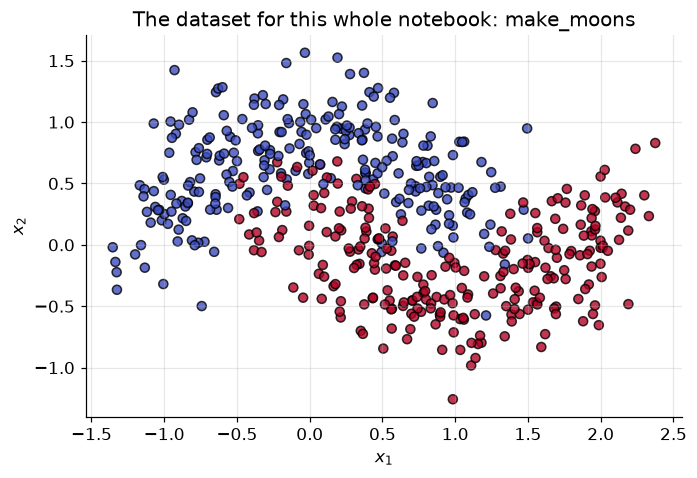

In [2]:
# Two interleaving crescents -- not linearly separable, small enough to train instantly
X, y = make_moons(n_samples=500, noise=0.25, random_state=RANDOM_STATE)
y = y.reshape(-1, 1).astype(float)

# One split, reused everywhere: 70% train, 15% validation, 15% test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.15, random_state=RANDOM_STATE, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.15 / 0.85, random_state=RANDOM_STATE, stratify=y_train)

# Standardise using train-set statistics only
mu, sigma = X_train.mean(axis=0), X_train.std(axis=0)
X_train_s = (X_train - mu) / sigma
X_val_s = (X_val - mu) / sigma
X_test_s = (X_test - mu) / sigma

print(f"train: {X_train.shape[0]}   validation: {X_val.shape[0]}   test: {X_test.shape[0]}")

plt.scatter(X[:, 0], X[:, 1], c=y.ravel(), cmap="coolwarm", edgecolor="k", alpha=0.8, s=35)
plt.title("The dataset for this whole notebook: make_moons")
plt.xlabel("$x_1$"); plt.ylabel("$x_2$")
plt.show()

---
## 1. The single neuron: logistic regression with a new name

Look closely and a biological neuron is a small piece of wiring: dendrites collect signals from other
neurons, the cell body combines them, and if the combined signal is strong enough, the axon fires a signal of
its own down the line to the next neuron. An **artificial neuron** copies exactly this shape, replacing
"strong enough" with arithmetic:

<div align="center">
<img src="resources/images/nn_perceptron_diagram.png" width="620">

*Figure 1 — A single artificial neuron: weighted inputs, a bias, a sum, and an output.*
</div>

Every input $x_i$ arrives carrying its own **weight** $w_i$ — how much that input matters. The neuron adds a
**bias** $b$ (a constant, always-on input worth its own weight), sums everything up, and — this is the whole
trick — passes the sum through an **activation function** $f$ before handing off the result:

$$z = b + \sum_{i=1}^{n} w_i x_i \qquad\qquad a = f(z)$$

Stop and look at $z$ on its own, before the activation function touches it: $z = b + w_1 x_1 + \cdots + w_n
x_n$. That is *exactly* the linear regression equation from the very first modules of this course, with
$\beta$ renamed to $w$. And if we let $f$ be the sigmoid function, $a = \sigma(z) = \frac{1}{1+e^{-z}}$, then
$a$ is *exactly* the logistic regression from the Classification module. A single neuron with a sigmoid
activation **is** a logistic regression, expressed in a new vocabulary that happens to generalise beautifully:
"neuron", "weight" and "activation" all still make sense once we have thousands of them wired together, while
"coefficient" starts to feel cramped.

In [3]:
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

# One neuron == one logistic regression: a weighted sum of two features, run through sigmoid
w = np.array([1.5, -2.0])   # arbitrary weights, just to demonstrate the mechanics
b = 0.3

x_example = X_train_s[0]
z = b + w @ x_example
a = sigmoid(z)

print(f"inputs           x = {x_example.round(3)}")
print(f"weighted sum      z = b + w.x = {z:.4f}")
print(f"activation        a = sigmoid(z) = {a:.4f}")
print(f"true label            y = {y_train[0, 0]:.0f}")

inputs           x = [ 0.192 -1.253]
weighted sum      z = b + w.x = 3.0936
activation        a = sigmoid(z) = 0.9566
true label            y = 1


Nothing new has happened computationally — we've just watched a logistic regression classify one point. What
*is* new is the name "neuron", and the promise that comes with it: a neuron is a Lego brick. The next section
asks the obvious question — what happens when we snap several of them together?

---
## 2. Why one neuron isn't enough: the case for hidden layers

A single neuron, sigmoid or not, can only ever draw a **straight decision boundary** (or a flat hyperplane in
higher dimensions) through the data — the "linearly separable" boundary the Classification module already
introduced. Some data simply doesn't cooperate:

<div align="center">
<img src="resources/images/nn_linear_vs_nonlinear_separable.png" width="640">

*Figure 2 — Linearly separable data admits a straight-line boundary; ours won't.*
</div>

Our `make_moons` data is the unseparable kind by construction — two crescents that curl into each other. Let's
watch a plain logistic regression try anyway.

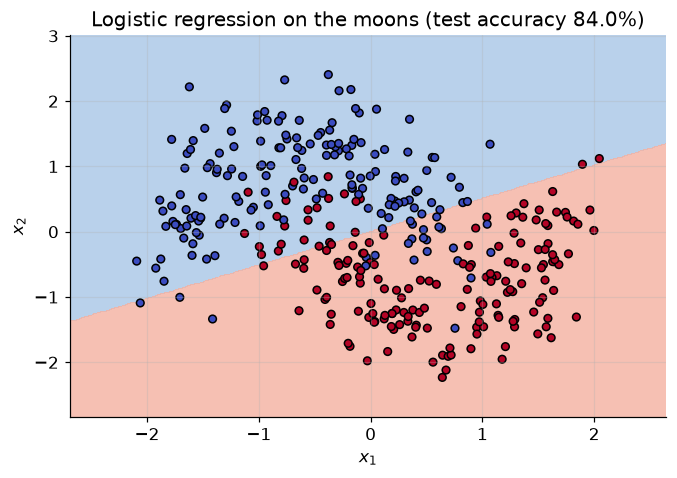

In [4]:
def plot_decision_boundary(model_predict, X, y, ax=None, title=""):
    '''Colour the 2-D input space by predicted class, with the data scattered on top.'''
    ax = ax or plt.gca()
    x_min, x_max = X[:, 0].min() - 0.6, X[:, 0].max() + 0.6
    y_min, y_max = X[:, 1].min() - 0.6, X[:, 1].max() + 0.6
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
    grid = np.c_[xx.ravel(), yy.ravel()]
    preds = model_predict(grid).reshape(xx.shape)
    ax.contourf(xx, yy, preds, levels=[-0.1, 0.5, 1.1], colors=["#a8c6e6", "#f4b1a0"], alpha=0.8)
    ax.scatter(X[:, 0], X[:, 1], c=y.ravel(), cmap="coolwarm", edgecolor="k", s=25)
    ax.set_title(title)
    ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")

logreg = LogisticRegression().fit(X_train_s, y_train.ravel())
logreg_acc = accuracy_score(y_test, logreg.predict(X_test_s))

plot_decision_boundary(logreg.predict, X_train_s, y_train,
                        title=f"Logistic regression on the moons (test accuracy {logreg_acc:.1%})")
plt.show()

A single straight line, doing its best, cutting straight through the crescents it can't tell apart. This isn't
a bug in logistic regression — it's a hard mathematical limit of *any* single linear-plus-activation neuron,
no matter how we tune its weights.

The tempting fix is to chain several linear layers together *without* anything non-linear between them. It
doesn't work, and it's worth seeing why in one line of algebra. Suppose layer 1 computes
$z^{(1)} = W^{(1)}x + b^{(1)}$ and layer 2 computes $z^{(2)} = W^{(2)}z^{(1)} + b^{(2)}$ directly on that
output. Substitute:

$$z^{(2)} = W^{(2)}\left(W^{(1)}x + b^{(1)}\right) + b^{(2)} = \underbrace{W^{(2)}W^{(1)}}_{W'}x +
\underbrace{W^{(2)}b^{(1)} + b^{(2)}}_{b'} = W'x + b'$$

Two linear layers collapse into one linear layer with different numbers — no matter how many you stack, you
still only ever get a straight line. The fix is exactly the activation function each neuron already carries:
slot a **non-linear** function ($\sigma$, tanh, ReLU — Section 5 covers the options) between the layers, and
the collapse above no longer happens. A **hidden layer** of several such neurons, each drawing its own
(non-linear-adjacent) boundary, lets the *next* layer combine those boundaries into shapes a single neuron
could never draw — including two interlocking crescents.

---
## 3. Computational graphs and the chain rule

Before we can train a network of neurons we need a general way to answer one question: *if I nudge this
weight, buried three layers deep, how does the final loss move?* The tool for this is the same one from
first-year calculus, dressed up as a diagram: the **computational graph**. Every arithmetic operation becomes
a node; every value flowing between operations becomes an edge. Here is the smallest possible example,
$y = 2x + a$, drawn as a graph instead of an equation:

<div align="center">
<img src="resources/images/nn_computational_graph_simple.png" width="700">

*Figure 3 — A computational graph: each node is one operation, each edge carries a value forward.*
</div>

Running the graph left-to-right (the arrows as drawn) is the **forward pass** — exactly what `sigmoid(b + w
@ x)` did in Section 1. The reason to bother drawing the graph at all is what it buys us going the *other*
direction. Every node in the graph knows only its own **local gradient** — the derivative of its own output
with respect to its own inputs, a fact it can compute without knowing anything about the rest of the network:

<div align="center">
<img src="resources/images/nn_backprop_local_gradient.png" width="700">

*Figure 4 — Every node's local gradient, and the chain rule gluing them together across an edge.*
</div>

The **chain rule** says the gradient of the final loss $L$ with respect to any upstream value is just the
product of local gradients along the path connecting them: $\frac{\partial L}{\partial x} = \frac{\partial
L}{\partial Z}\cdot\frac{\partial Z}{\partial x}$. A node doesn't need to understand the whole network — it
only ever multiplies "the gradient handed to me from downstream" by "my own local gradient," and passes the
product further upstream. Backpropagation, which we build in the next section, is nothing but this rule
applied once per node, walking the graph backward from the loss to every weight.

Let's make this concrete with the smallest network we have: one neuron, sigmoid activation, binary
cross-entropy loss — precisely Section 1's neuron, with a loss bolted on the end.

<div align="center">
<img src="resources/images/nn_computational_graph_logistic.png" width="620">

*Figure 5 — Forward pass through a single sigmoid neuron into a binary cross-entropy loss.*
</div>

In [5]:
def forward_neuron(w0, w1, w2, x1, x2):
    '''One sigmoid neuron: z = w0 + w1*x1 + w2*x2 ,  yhat = sigmoid(z).'''
    z = w0 + w1 * x1 + w2 * x2
    yhat = sigmoid(z)
    return z, yhat

def bce_loss(y, yhat, eps=1e-12):
    return -(y * np.log(yhat + eps) + (1 - y) * np.log(1 - yhat + eps))

# An arbitrary toy example -- small enough to hand-check
w0, w1, w2 = 0.10, 0.40, -0.20
x1, x2, y_true = 2.0, 3.0, 1.0

z, yhat = forward_neuron(w0, w1, w2, x1, x2)
L = bce_loss(y_true, yhat)
print(f"z    = {z:.4f}")
print(f"yhat = {yhat:.4f}")
print(f"L    = {L:.4f}")

z    = 0.3000
yhat = 0.5744
L    = 0.5544


Now walk backward through the graph exactly as Figure 4 prescribes: each arrow contributes one local gradient,
and the chain rule multiplies them together node by node.

$$\frac{\partial L}{\partial \hat y}=-\left(\frac{y}{\hat y}-\frac{1-y}{1-\hat y}\right)
\qquad\quad \frac{\partial \hat y}{\partial z}=\hat y(1-\hat y)
\qquad\quad \frac{\partial z}{\partial w_0}=1,\ \ \frac{\partial z}{\partial w_1}=x_1,\ \ \frac{\partial
z}{\partial w_2}=x_2$$

$$\frac{\partial L}{\partial w_i} = \underbrace{\frac{\partial L}{\partial \hat y}\cdot\frac{\partial \hat
y}{\partial z}}_{\text{shared by every weight}} \cdot\ \frac{\partial z}{\partial w_i}$$

The first product, $\frac{\partial L}{\partial \hat y}\cdot\frac{\partial \hat y}{\partial z}$, doesn't depend
on *which* weight we're differentiating — it's computed once at the loss and reused for every weight upstream.
That's the entire computational payoff of backpropagation: shared work is computed once and multiplied out,
rather than re-derived from scratch for every one of possibly millions of weights.

In [6]:
dL_dyhat = -(y_true / yhat - (1 - y_true) / (1 - yhat))
dyhat_dz = yhat * (1 - yhat)
dL_dz = dL_dyhat * dyhat_dz                      # the "shared" upstream gradient

dz_dw0, dz_dw1, dz_dw2 = 1.0, x1, x2
grads_by_hand = {
    "w0": dL_dz * dz_dw0,
    "w1": dL_dz * dz_dw1,
    "w2": dL_dz * dz_dw2,
}
print("hand-derived gradients:", {k: round(v, 4) for k, v in grads_by_hand.items()})

# Sanity check against finite differences: nudge each weight by +-eps, remeasure the loss
eps = 1e-6
grads_numeric = {}
for name, w_val in zip(["w0", "w1", "w2"], [w0, w1, w2]):
    kwargs_plus = dict(w0=w0, w1=w1, w2=w2, x1=x1, x2=x2)
    kwargs_minus = dict(w0=w0, w1=w1, w2=w2, x1=x1, x2=x2)
    kwargs_plus[name] = w_val + eps
    kwargs_minus[name] = w_val - eps
    _, yhat_plus = forward_neuron(**kwargs_plus)
    _, yhat_minus = forward_neuron(**kwargs_minus)
    L_plus = bce_loss(y_true, yhat_plus)
    L_minus = bce_loss(y_true, yhat_minus)
    grads_numeric[name] = (L_plus - L_minus) / (2 * eps)

print("finite-difference check:", {k: round(v, 4) for k, v in grads_numeric.items()})
max_diff = max(abs(grads_by_hand[k] - grads_numeric[k]) for k in grads_by_hand)
print(f"largest disagreement: {max_diff:.2e}  (should be tiny)")

hand-derived gradients: {'w0': np.float64(-0.4256), 'w1': np.float64(-0.8511), 'w2': np.float64(-1.2767)}
finite-difference check: {'w0': np.float64(-0.4256), 'w1': np.float64(-0.8511), 'w2': np.float64(-1.2767)}
largest disagreement: 1.20e-10  (should be tiny)


The hand-derived chain-rule gradients and the finite-difference estimates agree to several decimal places —
which is exactly the point. Backpropagation isn't a different, approximate way of getting the gradient; it's
an *efficient, exact* way of computing the same gradient that finite differences estimates one clumsy nudge
at a time. Notice also that $\frac{\partial z}{\partial w_i} = x_i$: a weight attached to a larger input
always receives a proportionally larger share of the blame (or credit) for the final loss — a fact worth
remembering when Section 6 asks how weights should be *initialised*.

---
## 4. Backpropagation: training a multi-layer network

One neuron's gradient was three lines of algebra. A hidden layer adds one more stop for the chain rule to pass
through — conceptually identical, just one hop longer. Consider the smallest possible hidden-layer network:
two inputs, two hidden neurons, one output neuron, all the way to a loss $E$:

<div align="center">
<img src="resources/images/nn_backprop_chain_rule.png" width="620">

*Figure 6 — A two-layer network: inputs $\to$ hidden layer $\to$ output $\to$ loss.*
</div>

Write $z^{(1)}, a^{(1)}$ for the hidden layer's pre-activation and activation, and $z^{(2)}, a^{(2)}$ for the
output layer's (using the superscript-in-parentheses-for-layer, subscript-for-node convention this whole
field uses). The **forward pass** is two applications of the same weighted-sum-plus-activation block from
Section 1, back to back:

$$z^{(1)} = X W^{(1)} + b^{(1)} \qquad a^{(1)} = f\!\left(z^{(1)}\right)
\qquad\qquad z^{(2)} = a^{(1)} W^{(2)} + b^{(2)} \qquad a^{(2)} = \sigma\!\left(z^{(2)}\right)$$

where $f$ is the hidden layer's activation function (Section 5 picks one) and $\sigma$ is sigmoid, giving a
binary prediction $\hat y = a^{(2)}$. The **backward pass** walks the same chain rule from Section 3 backward
through *two* stops instead of one. For binary cross-entropy loss with a sigmoid output, the first stop
simplifies beautifully (the $\hat y(1-\hat y)$ term from Section 3 cancels against the loss's own derivative):

$$\delta^{(2)} = \frac{\partial L}{\partial z^{(2)}} = a^{(2)} - y
\qquad\qquad \frac{\partial L}{\partial W^{(2)}} = {a^{(1)}}^{\!\top}\delta^{(2)}
\qquad\qquad \frac{\partial L}{\partial b^{(2)}} = \sum \delta^{(2)}$$

The output layer's error signal $\delta^{(2)}$ now has to travel one hop further back, through $W^{(2)}$ and
through the hidden layer's own activation function:

$$\delta^{(1)} = \left(\delta^{(2)} {W^{(2)}}^{\!\top}\right) \circ f'\!\left(z^{(1)}\right)
\qquad\qquad \frac{\partial L}{\partial W^{(1)}} = X^{\top}\delta^{(1)}
\qquad\qquad \frac{\partial L}{\partial b^{(1)}} = \sum \delta^{(1)}$$

($\circ$ is elementwise multiplication.) Read $\delta^{(1)}$ as "how much of the output's error is this hidden
neuron responsible for": the error is pulled back through the same weights it was pushed forward through
($W^{(2)\top}$), then gated by the hidden activation's own local gradient $f'(z^{(1)})$ — precisely the "local
gradient times incoming gradient" rule from Section 3, just applied at a second node. Every weight update then
follows the same rule we've used since the Gradient Descent module: **new weight = old weight $-\ \alpha
\times$ gradient.**

Let's implement exactly this — forward pass, backward pass, weight update — as plain NumPy, and prove it's
correct with a numerical gradient check before we trust it with real data.

In [7]:
def relu(z):
    return np.maximum(0, z)

def relu_deriv(z):
    return (z > 0).astype(float)

def init_params(n_in, n_hidden, n_out, scale=1.0, seed=RANDOM_STATE):
    '''Random weights (scaled by `scale`), zero biases. Section 6 revisits `scale`.'''
    rng = np.random.default_rng(seed)
    return {
        "W1": rng.standard_normal((n_in, n_hidden)) * scale,
        "b1": np.zeros((1, n_hidden)),
        "W2": rng.standard_normal((n_hidden, n_out)) * scale,
        "b2": np.zeros((1, n_out)),
    }

def forward(X, p):
    z1 = X @ p["W1"] + p["b1"]
    a1 = relu(z1)
    z2 = a1 @ p["W2"] + p["b2"]
    a2 = sigmoid(z2)
    cache = {"z1": z1, "a1": a1, "z2": z2, "a2": a2}
    return a2, cache

def compute_loss(y, a2, p=None, l2=0.0):
    m = y.shape[0]
    eps = 1e-12
    data_loss = -np.mean(y * np.log(a2 + eps) + (1 - y) * np.log(1 - a2 + eps))
    reg = 0.0
    if p is not None and l2 > 0:
        reg = (l2 / (2 * m)) * (np.sum(p["W1"] ** 2) + np.sum(p["W2"] ** 2))
    return data_loss + reg

def backward(X, y, p, cache, l2=0.0):
    m = X.shape[0]
    a1, a2, z1 = cache["a1"], cache["a2"], cache["z1"]

    dz2 = (a2 - y) / m                                        # delta^(2), averaged over the batch
    dW2 = a1.T @ dz2 + (l2 / m) * p["W2"]
    db2 = dz2.sum(axis=0, keepdims=True)

    da1 = dz2 @ p["W2"].T
    dz1 = da1 * relu_deriv(z1)                                # delta^(1)
    dW1 = X.T @ dz1 + (l2 / m) * p["W1"]
    db1 = dz1.sum(axis=0, keepdims=True)

    return {"W1": dW1, "b1": db1, "W2": dW2, "b2": db2}

Three functions, each a direct translation of one equation above: `forward` runs the two weighted-sum-plus-
activation steps, `backward` computes $\delta^{(2)}$ then $\delta^{(1)}$ and turns both into weight gradients.
Before we trust this code with real training, let's hold it to the same standard as any hand-derived formula:
compare it against a brute-force finite-difference estimate, on a tiny random network where mistakes have
nowhere to hide.

In [8]:
def gradient_check(n_in=3, n_hidden=4, n_out=1, n_samples=5, l2=0.1, seed=1):
    rng = np.random.default_rng(seed)
    Xg = rng.standard_normal((n_samples, n_in))
    yg = rng.integers(0, 2, size=(n_samples, n_out)).astype(float)
    p = init_params(n_in, n_hidden, n_out, scale=1.0, seed=seed + 1)

    a2, cache = forward(Xg, p)
    analytic_grads = backward(Xg, yg, p, cache, l2=l2)

    eps = 1e-5
    max_rel_error = 0.0
    for key in p:
        it = np.nditer(p[key], flags=["multi_index"])
        for _ in it:
            idx = it.multi_index
            original = p[key][idx]

            p[key][idx] = original + eps
            a2_plus, _ = forward(Xg, p)
            loss_plus = compute_loss(yg, a2_plus, p, l2=l2)

            p[key][idx] = original - eps
            a2_minus, _ = forward(Xg, p)
            loss_minus = compute_loss(yg, a2_minus, p, l2=l2)

            p[key][idx] = original
            numeric_grad = (loss_plus - loss_minus) / (2 * eps)
            analytic_grad = analytic_grads[key][idx]
            rel_error = abs(numeric_grad - analytic_grad) / (abs(numeric_grad) + abs(analytic_grad) + 1e-12)
            max_rel_error = max(max_rel_error, rel_error)
    return max_rel_error

max_rel_error = gradient_check()
print(f"largest relative error between analytic and numeric gradients: {max_rel_error:.2e}")
assert max_rel_error < 1e-6, "gradient check failed -- backward() disagrees with the numeric estimate"
print("backward() matches finite differences: the implementation is correct.")

largest relative error between analytic and numeric gradients: 1.07e-09
backward() matches finite differences: the implementation is correct.


That assertion passing is the whole point of a gradient check: it's the automated-testing equivalent of
Section 3's by-hand verification, run once over *every* weight in the network instead of three by hand. From
here on, `forward` and `backward` are trustworthy building blocks — Sections 5 through 9 will each extend one
piece of them (a different activation, a smarter initialisation, a fancier optimizer, a normalization layer, a
regularizer) without ever having to re-derive the chain rule from scratch.

---
## 5. Activation functions: choosing the squash

Section 2 established that *some* non-linearity between layers is non-negotiable. It didn't say which one.
Here is where the hidden layer's activation function gets slotted in — the same $f$ from Section 4's forward
pass:

<div align="center">
<img src="resources/images/nn_activation_function_placement.png" width="640">

*Figure 7 — The activation function sits right after each neuron's weighted sum, before the result moves on.*
</div>

**Sigmoid**, $\sigma(z)=\frac{1}{1+e^{-z}}$, is where this module started (Section 1) and remains the right
choice for a *binary output* layer, because its range $(0,1)$ reads directly as a probability. Its derivative,
$\sigma'(z) = \sigma(z)(1-\sigma(z))$, has a serious flaw for *hidden* layers, though: it peaks at $0.25$
(when $\sigma(z)=0.5$) and decays toward zero the moment $|z|$ grows — a saturated sigmoid neuron passes back
almost no gradient at all. Stack several sigmoid hidden layers and the chain rule from Section 4 multiplies
several of these small numbers together; the product shrinks toward zero exponentially fast. This is the
**vanishing gradient problem**, and it's the main reason sigmoid fell out of favour for hidden layers.

**Tanh**, $\tanh(z)=\frac{1-e^{-2z}}{1+e^{-2z}}$, is sigmoid's zero-centred cousin: range $(-1, 1)$, derivative
$1-\tanh^2(z)$, peak derivative $1.0$ instead of $0.25$. Better than sigmoid for hidden layers, but it still
saturates (and still vanishes) for large $|z|$.

**ReLU**, $R(z) = \max(0, z)$, sidesteps saturation on the positive side entirely — its derivative is a flat
$1$ for any $z>0$, so the chain rule stops shrinking gradients through active units no matter how deep the
network gets. That's traded for a new failure mode: any neuron whose weighted sum is permanently negative has
derivative exactly $0$ and **stops learning forever** — the "dying ReLU" problem. **Leaky ReLU** patches this
with a small non-zero slope on the negative side, $f(z) = z$ if $z\geq 0$ else $\alpha z$ (typically
$\alpha=0.01$), keeping a faint gradient alive everywhere.

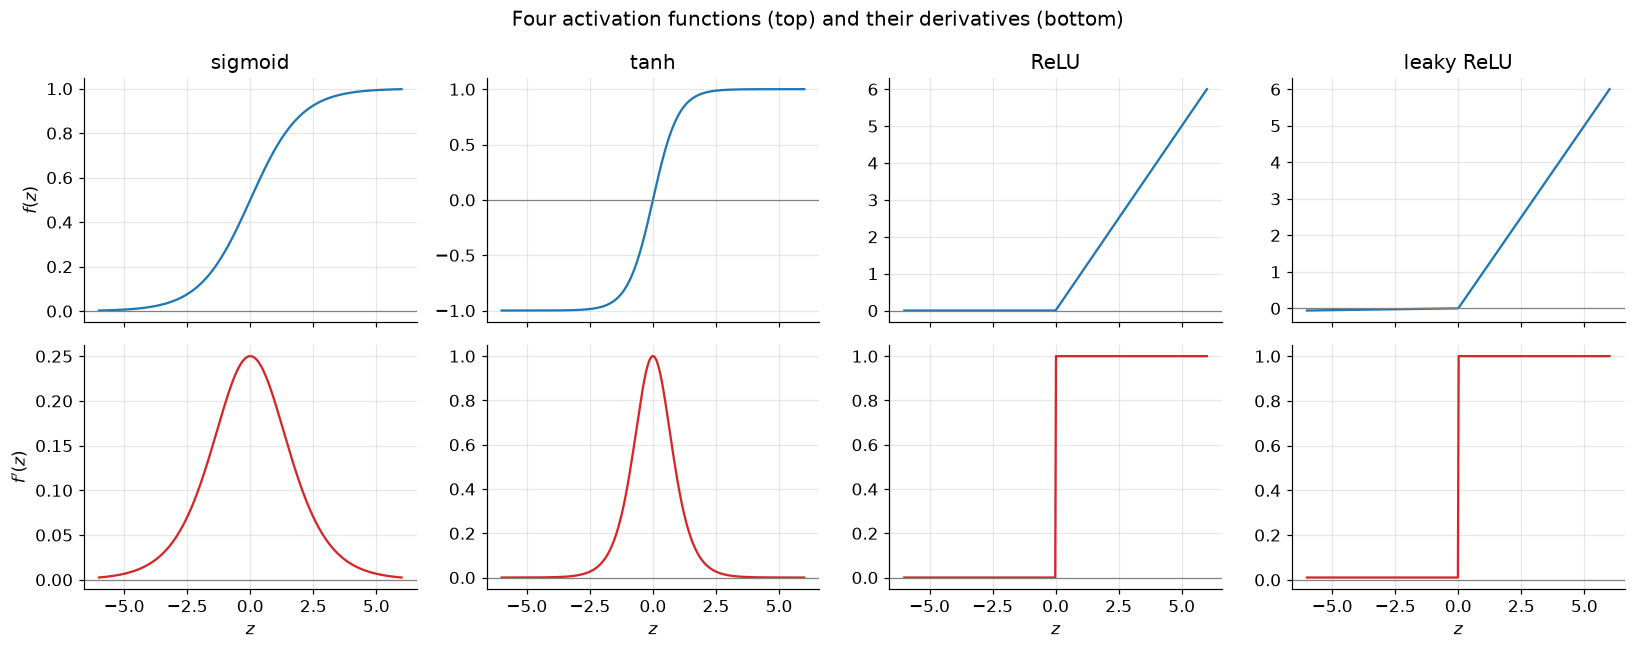

peak derivative:   {'sigmoid': np.float64(0.25), 'tanh': np.float64(1.0), 'ReLU': np.float64(1.0), 'leaky ReLU': np.float64(1.0)}


In [9]:
def tanh(z):
    return np.tanh(z)

def tanh_deriv(z):
    return 1 - np.tanh(z) ** 2

def leaky_relu(z, alpha=0.01):
    return np.where(z >= 0, z, alpha * z)

def leaky_relu_deriv(z, alpha=0.01):
    return np.where(z >= 0, 1.0, alpha)

def sigmoid_deriv(z):
    s = sigmoid(z)
    return s * (1 - s)

z_grid = np.linspace(-6, 6, 400)
functions = {
    "sigmoid": (sigmoid, sigmoid_deriv),
    "tanh": (tanh, tanh_deriv),
    "ReLU": (relu, relu_deriv),
    "leaky ReLU": (leaky_relu, leaky_relu_deriv),
}

fig, axes = plt.subplots(2, 4, figsize=(15, 6), sharex=True)
for col, (name, (fn, deriv)) in enumerate(functions.items()):
    axes[0, col].plot(z_grid, fn(z_grid), color="tab:blue")
    axes[0, col].set_title(name)
    axes[0, col].axhline(0, color="grey", linewidth=0.8)
    axes[1, col].plot(z_grid, deriv(z_grid), color="tab:red")
    axes[1, col].axhline(0, color="grey", linewidth=0.8)
axes[0, 0].set_ylabel("$f(z)$")
axes[1, 0].set_ylabel("$f'(z)$")
for ax in axes[1, :]:
    ax.set_xlabel("$z$")
plt.suptitle("Four activation functions (top) and their derivatives (bottom)")
plt.tight_layout()
plt.show()

print("peak derivative:  ", {name: round(deriv(z_grid).max(), 3) for name, (fn, deriv) in functions.items()})

Read the bottom row as "how much gradient survives passing through this neuron." Sigmoid's derivative never
exceeds $0.25$ and is already close to zero by $|z|=4$; tanh does better but still collapses at the edges;
ReLU's derivative is a flat $1$ everywhere positive — no shrinkage at all, as long as the neuron stays active
— and leaky ReLU keeps a small trickle of gradient alive even on the negative side, where plain ReLU goes
completely flat. This is exactly why every hidden layer we train from here on uses ReLU: it's the one whose
derivative doesn't work against us as networks get deeper.

---
## 6. Weight initialization: starting somewhere sensible

`init_params` in Section 4 filled every weight from `rng.standard_normal(...) * scale` and quietly left
`scale` unexamined. It matters enormously. Two failure modes to rule out first:

- **All-zeros weights.** Every hidden neuron computes the identical weighted sum, gets the identical gradient,
  and stays identical forever — no amount of training breaks the symmetry. (Zero-initialising *biases* is
  fine, since the weights alone are what makes neurons different from each other.)
- **All-ones, or any other single constant** — same symmetry problem, different number.

Independent random weights break the symmetry, but "random" alone doesn't say *how big*. Recall Section 3's
observation that a weight's gradient scales with its input — the flip side is that a neuron's *output* scales
with the size of its weights, layer after layer. Get the scale wrong and the signal either explodes or
vanishes as it propagates through depth, entirely independently of the vanishing-gradient story in Section 5.
Let's watch both failures happen, live, in a deep (but otherwise untrained) network.

In [10]:
def propagate_forward(weight_scale_fn, activation, n_layers=6, width=200, seed=RANDOM_STATE):
    '''Push random data through `n_layers` untrained layers and track what happens to it.'''
    rng = np.random.default_rng(seed)
    a = rng.standard_normal((1000, width)) * 0.5
    stats = []
    for _ in range(n_layers):
        W = rng.standard_normal((width, width)) * weight_scale_fn(width)
        z = a @ W
        a = activation(z)
        if activation is relu:
            dead_frac = np.mean(a == 0)
            stats.append((a.std(), dead_frac))
        else:
            saturated_frac = np.mean(np.abs(a) > 0.99)
            stats.append((a.std(), saturated_frac))
    return stats

naive_relu_stats = propagate_forward(lambda n: 1.0, relu)
he_relu_stats = propagate_forward(lambda n: np.sqrt(2.0 / n), relu)

report = pd.DataFrame({
    "naive N(0,1), std":  [s for s, _ in naive_relu_stats],
    "naive N(0,1), % dead": [100 * f for _, f in naive_relu_stats],
    "He-scaled, std":      [s for s, _ in he_relu_stats],
    "He-scaled, % dead":   [100 * f for _, f in he_relu_stats],
}, index=[f"layer {i+1}" for i in range(len(naive_relu_stats))])
report.round(2)

,"naive N(0,1), std","naive N(0,1), % dead","He-scaled, std","He-scaled, % dead"
layer 1,4.14,50.13,0.41,50.13
layer 2,41.17,49.84,0.41,49.84
layer 3,400.09,49.62,0.40,49.62
layer 4,4006.14,49.97,0.40,49.97
layer 5,36390.34,52.74,0.36,52.74
layer 6,337141.31,47.89,0.34,47.89


With plain `N(0,1)` weights, the activations' standard deviation multiplies by roughly $\sqrt{\text{width}}$
at *every* layer — by the last layer it has run away to a number with several more digits than it started
with, purely from unlucky scaling, before a single gradient has been computed. The He-scaled network's
standard deviation instead settles into a stable, similar-sized band, layer after layer, with no such runaway
growth.

The fix follows directly from the same variance arithmetic that produced the blow-up: if each of a neuron's
$n_{in}$ inputs has variance $\text{Var}(x)$ and each weight is drawn independently, the pre-activation's
variance is $n_{in}\cdot\text{Var}(w)\cdot\text{Var}(x)$. Setting $\text{Var}(w) = \frac{1}{n_{in}}$ cancels
the $n_{in}$ exactly, keeping the signal's variance roughly constant layer to layer — this is **LeCun
initialization**. Two refinements adapt it to specific activations:

$$\textbf{Xavier / Glorot (tanh, sigmoid):}\quad \text{Var}(w) = \frac{2}{n_{in}+n_{out}}
\qquad\qquad
\textbf{He (ReLU family):}\quad \text{Var}(w) = \frac{2}{n_{in}}$$

He initialization doubles LeCun's variance because ReLU zeroes out roughly half its inputs (everything
negative) — the surviving half needs twice the variance to carry the same amount of signal forward. Xavier
instead balances the *forward* signal (which cares about $n_{in}$) against the *backward* gradient (which, by
the same argument applied to $\delta^{(1)}$ in Section 4, cares about $n_{out}$), by averaging the two.

In [11]:
def init_params_v2(n_in, n_hidden, n_out, method="he", seed=RANDOM_STATE):
    '''Weight initialisers: 'zeros', 'naive' (N(0,1)), 'xavier', or 'he'.'''
    rng = np.random.default_rng(seed)
    if method == "zeros":
        W1 = np.zeros((n_in, n_hidden)); W2 = np.zeros((n_hidden, n_out))
    elif method == "naive":
        W1 = rng.standard_normal((n_in, n_hidden)); W2 = rng.standard_normal((n_hidden, n_out))
    elif method == "xavier":
        W1 = rng.standard_normal((n_in, n_hidden)) * np.sqrt(2.0 / (n_in + n_hidden))
        W2 = rng.standard_normal((n_hidden, n_out)) * np.sqrt(2.0 / (n_hidden + n_out))
    elif method == "he":
        W1 = rng.standard_normal((n_in, n_hidden)) * np.sqrt(2.0 / n_in)
        W2 = rng.standard_normal((n_hidden, n_out)) * np.sqrt(2.0 / n_hidden)
    else:
        raise ValueError(f"unknown method: {method}")
    return {"W1": W1, "b1": np.zeros((1, n_hidden)), "W2": W2, "b2": np.zeros((1, n_out))}

for method in ["zeros", "naive", "xavier", "he"]:
    p = init_params_v2(2, 16, 1, method=method)
    print(f"{method:8s}  W1 std = {p['W1'].std():.4f}   W2 std = {p['W2'].std():.4f}")

zeros     W1 std = 0.0000   W2 std = 0.0000
naive     W1 std = 0.7986   W2 std = 0.8666
xavier    W1 std = 0.2662   W2 std = 0.2972
he        W1 std = 0.7986   W2 std = 0.3064


`init_params` from Section 4 will be replaced by this more deliberate version from here on — `he`
initialisation whenever the hidden layer uses ReLU (our default for the rest of the notebook), `xavier` if we
ever switch to tanh. Zero initialisation is kept only to remind ourselves never to use it.

---
## 7. Optimization algorithms: beyond plain gradient descent

Every weight update since the Gradient Descent module has had the same shape: $w \leftarrow w - \alpha\,
\frac{\partial L}{\partial w}$. It works, but it has a well-known weakness, illustrated by the classic
**ravine**: a loss surface that's steep in one direction and nearly flat in another (extremely common once a
network has more than a handful of weights). Plain gradient descent bounces sharply back and forth across the
steep direction while crawling along the shallow one — the learning rate that's *safe* for the steep direction
is far too small to make useful progress on the shallow one.

<div align="center">
<img src="resources/images/nn_gradient_descent_bowl.png" width="520">

*Figure 8 — Gradient descent takes small, jittery steps down a curved error surface toward the minimum.*
</div>

Every fix below shares one building block: the **exponentially weighted moving average (EWMA)**. Instead of
reacting to only the latest gradient, keep a running average that leans on recent history:

$$v_t = \beta v_{t-1} + (1-\beta)\,g_t$$

A $\beta$ close to $1$ averages over a long window (roughly the last $\frac{1}{1-\beta}$ steps — $\beta=0.9$
averages about 10 steps, $\beta=0.99$ about 100); a $\beta$ close to $0$ barely smooths at all. Three
optimizers apply this one idea in different places:

**Momentum** — average the *gradient itself*, then step in the averaged direction:
$$v_t = \beta v_{t-1} + (1-\beta)\,g_t \qquad\qquad w_t = w_{t-1} - \alpha\, v_t$$
A consistent downhill direction accumulates speed across steps (like a ball rolling downhill), while the
back-and-forth jitter across a ravine — which flips sign every step — mostly cancels out in the average.

**RMSprop** — instead average the *squared* gradient, and use it to rescale the learning rate per-parameter:
$$s_t = \beta s_{t-1} + (1-\beta)\,g_t^2 \qquad\qquad w_t = w_{t-1} - \alpha\, \frac{g_t}{\sqrt{s_t}+\epsilon}$$
A parameter with a history of large gradients (the steep ravine direction) gets its effective step size
shrunk; one with small, timid gradients (the shallow direction) gets its step size boosted. ($\epsilon\approx
10^{-8}$ only prevents division by zero.)

**Adam** — momentum and RMSprop, combined, plus a bias correction for the first few steps (when both running
averages start at zero and are biased toward it):
$$m_t = \beta_1 m_{t-1} + (1-\beta_1)g_t \qquad v_t = \beta_2 v_{t-1}+(1-\beta_2)g_t^2$$
$$\hat m_t = \frac{m_t}{1-\beta_1^t} \qquad \hat v_t = \frac{v_t}{1-\beta_2^t}
\qquad\qquad w_t = w_{t-1} - \alpha\,\frac{\hat m_t}{\sqrt{\hat v_t}+\epsilon}$$
with standard defaults $\beta_1=0.9$, $\beta_2=0.999$. Adam is the closest thing deep learning has to a
default choice, and it's what we'll train our own network with in Section 11.

Let's race all four down an actual ravine and watch what "shrink the effective step in the steep direction"
buys in practice.

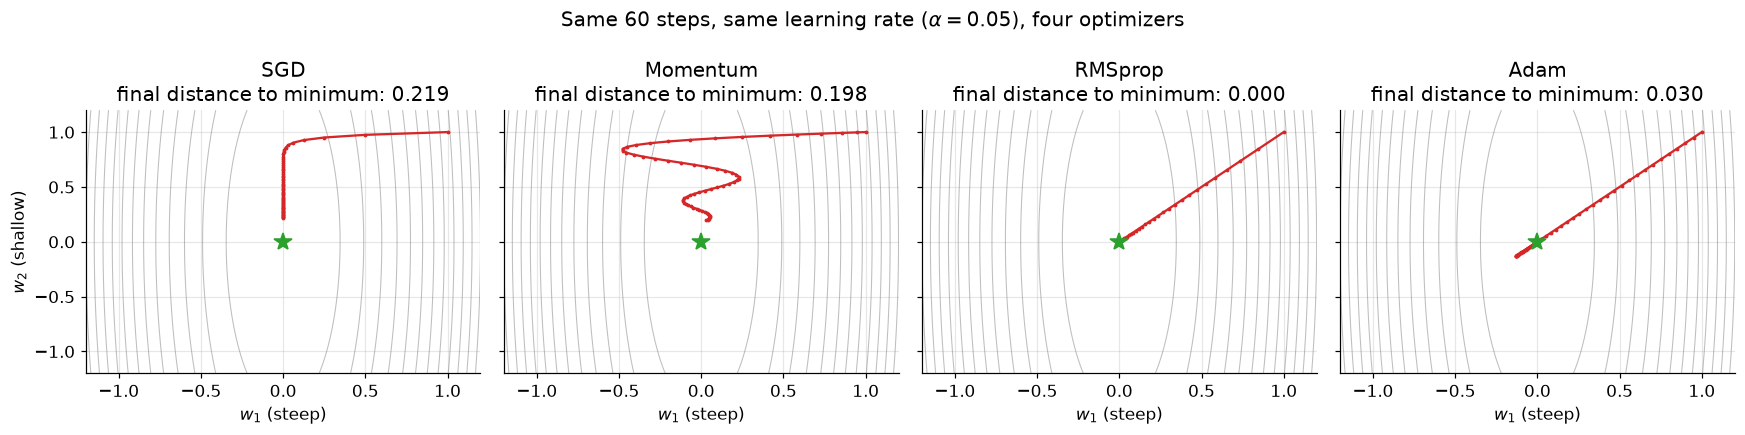

In [12]:
A = np.array([10.0, 0.5])   # steep in w1, shallow in w2

def ravine_grad(w):
    return A * w

def run_optimizer(update_fn, w0, n_steps=60, lr=0.05):
    w = w0.copy()
    state = {}
    path = [w.copy()]
    for t in range(1, n_steps + 1):
        g = ravine_grad(w)
        w, state = update_fn(w, g, state, t, lr)
        path.append(w.copy())
    return np.array(path)

def sgd_step(w, g, state, t, lr):
    return w - lr * g, state

def momentum_step(w, g, state, t, lr, beta=0.9):
    v = state.get("v", np.zeros_like(w))
    v = beta * v + (1 - beta) * g
    return w - lr * v, {"v": v}

def rmsprop_step(w, g, state, t, lr, beta=0.9, eps=1e-8):
    s = state.get("s", np.zeros_like(w))
    s = beta * s + (1 - beta) * g ** 2
    return w - lr * g / (np.sqrt(s) + eps), {"s": s}

def adam_step(w, g, state, t, lr, beta1=0.9, beta2=0.999, eps=1e-8):
    m = state.get("m", np.zeros_like(w))
    v = state.get("v", np.zeros_like(w))
    m = beta1 * m + (1 - beta1) * g
    v = beta2 * v + (1 - beta2) * g ** 2
    m_hat = m / (1 - beta1 ** t)
    v_hat = v / (1 - beta2 ** t)
    return w - lr * m_hat / (np.sqrt(v_hat) + eps), {"m": m, "v": v}

w0 = np.array([1.0, 1.0])
optimizers = {"SGD": sgd_step, "Momentum": momentum_step, "RMSprop": rmsprop_step, "Adam": adam_step}
paths = {name: run_optimizer(fn, w0) for name, fn in optimizers.items()}

# Contour of the ravine loss, with each optimizer's path overlaid
w1_grid, w2_grid = np.meshgrid(np.linspace(-1.2, 1.2, 200), np.linspace(-1.2, 1.2, 200))
loss_grid = 0.5 * (A[0] * w1_grid ** 2 + A[1] * w2_grid ** 2)

fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=True)
for ax, (name, path) in zip(axes, paths.items()):
    ax.contour(w1_grid, w2_grid, loss_grid, levels=12, colors="grey", alpha=0.5, linewidths=0.7)
    ax.plot(path[:, 0], path[:, 1], marker=".", markersize=3, color="tab:red")
    ax.plot(0, 0, marker="*", markersize=12, color="tab:green")
    ax.set_title(f"{name}\nfinal distance to minimum: {np.linalg.norm(path[-1]):.3f}")
    ax.set_xlabel("$w_1$ (steep)")
axes[0].set_ylabel("$w_2$ (shallow)")
plt.suptitle("Same 60 steps, same learning rate ($\\alpha=0.05$), four optimizers")
plt.tight_layout()
plt.show()

Plain SGD zig-zags sharply across the steep $w_1$ direction and barely dents the shallow $w_2$ direction in
the same 60 steps. Momentum smooths some of that zig-zag but is still governed by the same shared learning
rate. RMSprop and Adam — the two that rescale each direction *independently* — reach the minimum fastest,
because they're free to take a cautious step in $w_1$ and an aggressive one in $w_2$ at the same time. This is
the concrete payoff of "adaptive" optimizers, and why Adam is the default we reach for from Section 11 onward.

---
## 8. Normalizing activations: batch norm and layer norm

The Gradient Descent module already taught us to standardise the *inputs* before training —
$x_{scaled}=\frac{x-\mu}{\sigma}$ — because features on wildly different scales distort the loss surface into
exactly the kind of ravine Section 7 just fought to escape. The same problem re-appears one layer deeper: as
training proceeds, the *distribution* of each hidden layer's activations keeps shifting, because every layer
before it is also changing its weights (an effect nicknamed **internal covariate shift**). A hidden layer
chasing a constantly moving target learns more slowly and needs a smaller, more cautious learning rate.

**Batch normalization** applies the exact standardisation trick from Gradient Descent, but to a hidden layer's
activations instead of the raw inputs — computed fresh, per neuron, across every mini-batch:

$$\mu_B = \frac{1}{m}\sum_{i=1}^m x_i \qquad \sigma_B^2 = \frac{1}{m}\sum_{i=1}^m (x_i-\mu_B)^2
\qquad \hat x_i = \frac{x_i-\mu_B}{\sqrt{\sigma_B^2+\epsilon}} \qquad y_i = \gamma\hat x_i + \beta$$

<div align="center">
<img src="resources/images/nn_batchnorm_architecture.png" width="560">

*Figure 9 — Batch normalization sits between one neuron's weighted sum and the next layer, computed across
the batch.*
</div>

The learnable $\gamma,\beta$ at the end matter: always forcing zero-mean, unit-variance would forbid the
network from ever choosing to *saturate* a sigmoid on purpose, which is occasionally exactly what it needs. By
making the rescaling learnable, the network can recover the original distribution if that turns out to be
optimal, or keep the standardised one if it isn't.

In [13]:
def batch_norm(x_batch, gamma=1.0, beta=0.0, eps=1e-8):
    '''Normalise one neuron's activations across the batch dimension (axis 0).'''
    batch_mean = x_batch.mean(axis=0, keepdims=True)
    batch_var = x_batch.var(axis=0, keepdims=True)
    x_hat = (x_batch - batch_mean) / np.sqrt(batch_var + eps)
    return gamma * x_hat + beta, batch_mean, batch_var

# A tiny worked example: one neuron's raw output across a mini-batch of 4 samples
batch_of_one_neuron = np.array([[2.0], [4.0], [4.0], [6.0]])
normalized, batch_mean, batch_var = batch_norm(batch_of_one_neuron)

print(f"batch          : {batch_of_one_neuron.ravel()}")
print(f"batch mean     : {batch_mean.ravel()[0]:.4f}")
print(f"batch variance : {batch_var.ravel()[0]:.4f}")
print(f"normalized     : {normalized.ravel().round(4)}")

batch          : [2. 4. 4. 6.]
batch mean     : 4.0000
batch variance : 2.0000
normalized     : [-1.4142  0.      0.      1.4142]


At **test time** there is no "batch" to normalise against — predictions might arrive one at a time. The
standard fix is to track a running average of $\mu_B$ and $\sigma_B^2$ *during* training and use that fixed,
population-level estimate at inference instead. This also explains one of batch norm's quirks: because every
mini-batch gets normalised against *its own* slightly different statistics, training effectively injects a
small amount of noise into every layer — which turns out to act as a mild regularizer, a free side-effect on
top of the original goal of stabilising training.

Batch norm has one structural weakness: it needs a reasonably large, meaningfully-sized batch to estimate
$\mu_B,\sigma_B^2$ from, which breaks down for very small batches, online (one-sample-at-a-time) learning, or
sequence models where "batch" doesn't align cleanly with the network's structure. **Layer normalization** is
the fix: normalise across the *features within one sample* instead of across samples in a batch — exactly the
same formula, computed along the other axis:

<div align="center">
<img src="resources/images/nn_layernorm_architecture.png" width="560">

*Figure 10 — Layer normalization boxes the whole layer for one sample, instead of one neuron across the
batch.*
</div>

In [14]:
def layer_norm(x_sample_by_features, gamma=1.0, beta=0.0, eps=1e-8):
    '''Normalise across the feature dimension (axis 1) -- one sample at a time.'''
    sample_mean = x_sample_by_features.mean(axis=1, keepdims=True)
    sample_var = x_sample_by_features.var(axis=1, keepdims=True)
    x_hat = (x_sample_by_features - sample_mean) / np.sqrt(sample_var + eps)
    return gamma * x_hat + beta, sample_mean, sample_var

# The same four numbers, now read as one sample's four hidden-neuron activations
one_sample_four_neurons = np.array([[2.0, 4.0, 4.0, 6.0]])
normalized_ln, mu_ln, var_ln = layer_norm(one_sample_four_neurons)

print(f"activations    : {one_sample_four_neurons.ravel()}")
print(f"sample mean    : {mu_ln.ravel()[0]:.4f}")
print(f"sample variance: {var_ln.ravel()[0]:.4f}")
print(f"normalized     : {normalized_ln.ravel().round(4)}")
print()
print("Same four numbers, same arithmetic -- batch norm averaged them down a column (across samples),")
print("layer norm averages them along a row (across features of one sample). Layer norm needs no")
print("batch at all, which is exactly why it's the norm of choice for RNNs and online learning.")

activations    : [2. 4. 4. 6.]
sample mean    : 4.0000
sample variance: 2.0000
normalized     : [-1.4142  0.      0.      1.4142]

Same four numbers, same arithmetic -- batch norm averaged them down a column (across samples),
layer norm averages them along a row (across features of one sample). Layer norm needs no
batch at all, which is exactly why it's the norm of choice for RNNs and online learning.


---
## 9. Regularizing neural networks: early stopping and weight decay

A network with 256 hidden neurons has vastly more parameters than the two-crescent problem needs — plenty of
room to memorise the training set outright, the same overfitting story the Regularization module diagnosed
for polynomial regression, with the same signature: training loss keeps falling while validation loss
eventually turns around and rises. Let's watch it happen, training a deliberately oversized hidden layer with
plain gradient descent for far longer than necessary. (We track plain data loss here, not the regularized
objective `backward` actually minimises — mixing the two would make train and validation loss uncomparable,
since the penalty term scales with $1/m$ and the two sets have different sizes.)

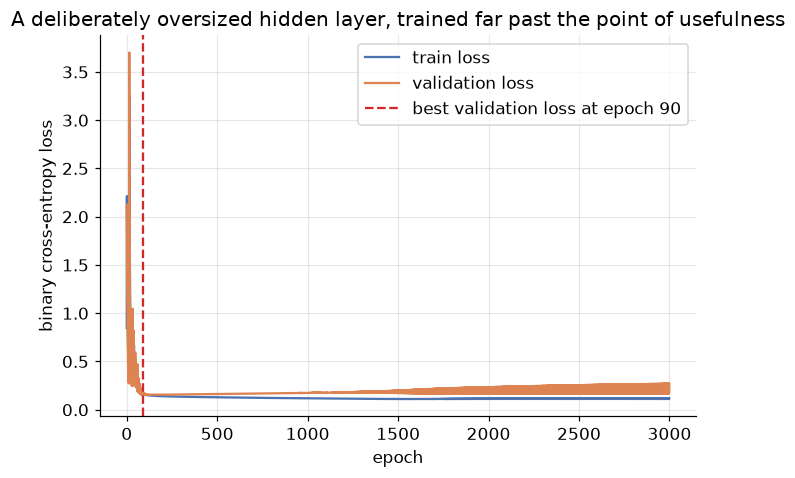

validation loss:  best = 0.1542 at epoch 90,  final = 0.2693 at epoch 2999
training loss:    at the same two points = 0.1610  and  0.1164


In [15]:
def full_batch_train(l2, n_hidden=256, lr=1.0, epochs=3000, seed=RANDOM_STATE):
    p = init_params_v2(2, n_hidden, 1, method="he", seed=seed)
    train_losses, val_losses = [], []
    for epoch in range(epochs):
        a2, cache = forward(X_train_s, p)
        grads = backward(X_train_s, y_train, p, cache, l2=l2)   # l2 still shapes the *gradient*
        for key in p:
            p[key] = p[key] - lr * grads[key]
        a2_val, _ = forward(X_val_s, p)
        train_losses.append(compute_loss(y_train, a2))          # but we *monitor* plain data loss
        val_losses.append(compute_loss(y_val, a2_val))
    return p, train_losses, val_losses

_, train_losses, val_losses = full_batch_train(l2=0.0)
best_epoch = int(np.argmin(val_losses))

plt.plot(train_losses, label="train loss")
plt.plot(val_losses, label="validation loss")
plt.axvline(best_epoch, color="tab:red", linestyle="--",
            label=f"best validation loss at epoch {best_epoch}")
plt.xlabel("epoch"); plt.ylabel("binary cross-entropy loss")
plt.title("A deliberately oversized hidden layer, trained far past the point of usefulness")
plt.legend()
plt.show()

print(f"validation loss:  best = {val_losses[best_epoch]:.4f} at epoch {best_epoch},  "
      f"final = {val_losses[-1]:.4f} at epoch {len(val_losses)-1}")
print(f"training loss:    at the same two points = {train_losses[best_epoch]:.4f}  and  {train_losses[-1]:.4f}")

Textbook overfitting: training loss keeps grinding downward for the full run, while validation loss finds its
best point early and then climbs back up as the network starts fitting noise specific to the training set.
**Early stopping** is the simplest possible fix — stop training (or roll back to) the weights from the epoch
with the best validation loss, rather than whatever epoch training happened to end on. In practice this is
implemented with a **patience** counter: keep training through minor wobbles, but if validation loss fails to
improve for `patience` consecutive epochs, stop and restore the best-seen weights. We'll wire exactly this
into the training loop in Section 11.

**Weight decay** attacks the same problem from a different angle — the Regularization module's "rent on
coefficients," transplanted. Recall ridge regression's cost function, $J = \text{SSE} + \lambda\sum w_j^2$;
differentiating the penalty term with respect to $w$ gives $\lambda w$, so its gradient-descent update is
$w \leftarrow w - \alpha\left(\frac{\partial L}{\partial w} + \lambda w\right)$ — at every step, every weight
gets nudged back toward zero by an amount proportional to its own size, on top of whatever the data-fitting
gradient wants. That is precisely the `l2` term already sitting in `backward()` since Section 4.

One subtlety worth flagging, because it trips people up: **weight decay and L2 regularization are only
identical under plain SGD.** The moment an optimizer like Adam rescales each parameter's step individually
(Section 7), the $\lambda w$ term gets rescaled right along with the gradient — which is *not* what "decay
every weight toward zero by the same proportion" was supposed to mean. Modern Adam implementations (often
labelled **AdamW**) fix this by applying the decay *after* the adaptive rescaling, decoupled from the gradient
step entirely: $w_t = w_{t-1} - \alpha\left(\frac{\hat m_t}{\sqrt{\hat v_t}+\epsilon} + \lambda w_{t-1}\right)$.
Something to know exists; not something this notebook needs to resolve, since our From-scratch network stays
small enough that plain L2 (inside `backward`) and decoupled weight decay behave almost identically in
practice.

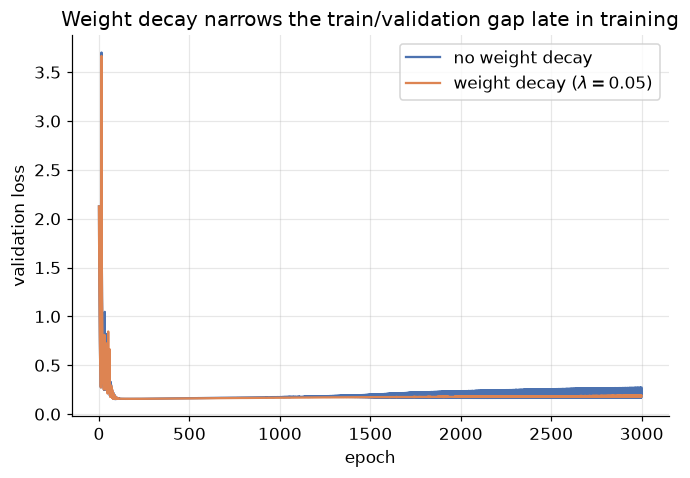

train/validation gap at epoch 2999:
  no weight decay  : 0.1529
  weight decay 0.05: 0.0794


In [16]:
_, train_losses_l2, val_losses_l2 = full_batch_train(l2=0.05)

plt.plot(val_losses, label="no weight decay")
plt.plot(val_losses_l2, label="weight decay ($\\lambda=0.05$)")
plt.xlabel("epoch"); plt.ylabel("validation loss")
plt.title("Weight decay narrows the train/validation gap late in training")
plt.legend()
plt.show()

gap_no_decay = val_losses[-1] - train_losses[-1]
gap_decay = val_losses_l2[-1] - train_losses_l2[-1]
print(f"train/validation gap at epoch {len(val_losses)-1}:")
print(f"  no weight decay  : {gap_no_decay:.4f}")
print(f"  weight decay 0.05: {gap_decay:.4f}")

Weight decay doesn't necessarily reach a *lower* minimum validation loss than an undecayed network stopped at
its best epoch — but notice how much narrower the gap between train and validation loss stays by the end of
training. Early stopping and weight decay attack the same overfitting problem from different directions, and
in practice a well-tuned network almost always uses both together, exactly as we will in Section 11.

---
## 10. Hyperparameter tuning: search strategies and learning-rate schedules

Every section so far has quietly introduced a new hyperparameter: hidden-layer width, activation function,
initialisation scheme, optimizer and its learning rate, weight-decay strength, early-stopping patience. None
of these are learned by gradient descent — they're chosen *before* training starts, and the wrong choice can
sink an otherwise-correct network. Trying combinations by hand doesn't scale past two or three knobs; two
systematic alternatives do.

**Grid search** lays out every hyperparameter's candidate values on a grid and evaluates *every* combination.
**Random search** instead draws a fixed number of combinations at random from the same ranges. The
perhaps-surprising result (Bergstra & Bengio, 2012) is that random search is usually the better use of a fixed
compute budget:

<div align="center">
<img src="resources/images/nn_grid_search.png" width="300">
<img src="resources/images/nn_random_search.png" width="300">

*Figure 11 — Grid search (left) spends every trial on a rigid lattice; random search (right) spreads the same
number of trials more freely across each hyperparameter's range.*
</div>

The reason: hyperparameters are rarely equally important. If (say) the learning rate matters far more than
batch size, a 4x4 grid only ever tests 4 *distinct* learning-rate values, no matter how many grid points you
add — the other 12 trials are wasted re-testing batch sizes at those same 4 learning rates. Random sampling
tests as many distinct values of *every* hyperparameter as there are trials, spending the budget where it's
more likely to pay off. Let's run both over our own network.

In [17]:
def train_eval(n_hidden, lr, l2=0.01, epochs=800, seed=RANDOM_STATE):
    '''Train briefly with plain gradient descent; return validation accuracy.'''
    p = init_params_v2(2, n_hidden, 1, method="he", seed=seed)
    for _ in range(epochs):
        a2, cache = forward(X_train_s, p)
        grads = backward(X_train_s, y_train, p, cache, l2=l2)
        for key in p:
            p[key] = p[key] - lr * grads[key]
    a2_val, _ = forward(X_val_s, p)
    return accuracy_score(y_val, (a2_val > 0.5).astype(int))

# Grid search: every combination of a small grid
hidden_grid = [4, 8, 16, 32]
lr_grid = [0.05, 0.2, 0.5, 1.0]
grid_results = [(nh, lr, train_eval(nh, lr)) for nh in hidden_grid for lr in lr_grid]
best_grid = max(grid_results, key=lambda r: r[2])

# Random search: the same budget (16 trials), sampled from the same ranges
rng = np.random.default_rng(RANDOM_STATE)
random_results = []
for _ in range(len(grid_results)):
    nh = int(rng.integers(4, 33))
    lr = float(10 ** rng.uniform(np.log10(0.05), np.log10(1.0)))   # log-uniform, same spirit as Section 6 of Regularization
    random_results.append((nh, lr, train_eval(nh, lr)))
best_random = max(random_results, key=lambda r: r[2])

print(f"grid search   ({len(grid_results)} trials):   best = hidden={best_grid[0]}, lr={best_grid[1]:.3f}  ->  val acc {best_grid[2]:.3f}")
print(f"random search ({len(random_results)} trials): best = hidden={best_random[0]}, lr={best_random[1]:.3f}  ->  val acc {best_random[2]:.3f}")

grid search   (16 trials):   best = hidden=16, lr=0.500  ->  val acc 0.960
random search (16 trials): best = hidden=6, lr=0.572  ->  val acc 0.947


Both strategies land in a similar neighbourhood here — this problem only has two hyperparameters and neither
dominates wildly, so grid search's weakness doesn't bite hard. The gap widens as the number of hyperparameters
grows; with five or six knobs, a grid fine enough to be useful becomes computationally impossible, while random
search's cost stays exactly as many trials as you can afford.

**Learning-rate scheduling** is a hyperparameter-tuning idea applied *during* a single training run rather than
across many: start with a larger $\alpha$ for fast early progress, then shrink it as training proceeds so later
updates don't overshoot a minimum the network is already close to. Three common schedules:

$$\textbf{Time-based decay:}\quad \alpha_{t+1} = \frac{\alpha_t}{1+\text{decay}\times t}
\qquad\quad
\textbf{Step decay:}\quad \alpha_{t} = \alpha_0 \times \text{decay\_rate}^{\lfloor t / \text{step} \rfloor}
\qquad\quad
\textbf{Exponential decay:}\quad \alpha_{t} = \alpha_0\, e^{-\text{decay}\times t}$$

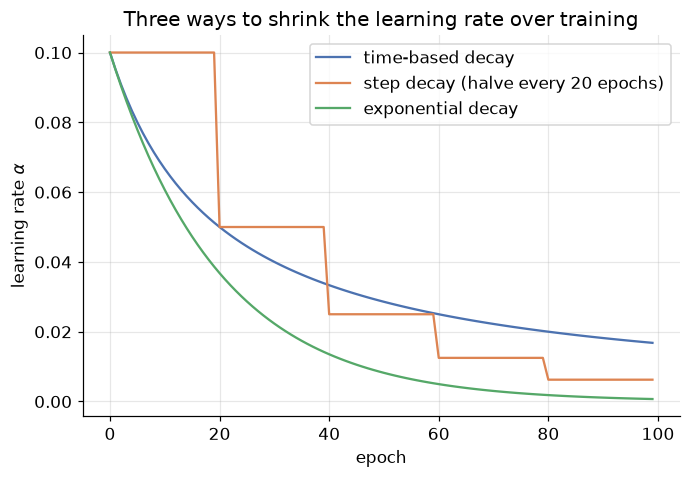

In [18]:
epochs_axis = np.arange(0, 100)
alpha0, decay = 0.1, 0.05

time_based = alpha0 / (1 + decay * epochs_axis)
step_decay = alpha0 * (0.5 ** (epochs_axis // 20))
exp_decay = alpha0 * np.exp(-decay * epochs_axis)

plt.plot(epochs_axis, time_based, label="time-based decay")
plt.plot(epochs_axis, step_decay, label="step decay (halve every 20 epochs)")
plt.plot(epochs_axis, exp_decay, label="exponential decay")
plt.xlabel("epoch"); plt.ylabel("learning rate $\\alpha$")
plt.title("Three ways to shrink the learning rate over training")
plt.legend()
plt.show()

All three tell the same story with a different curve shape: aggressive early steps, gentler ones later. Which
schedule (or none at all — Adam's own per-parameter rescaling already provides some of this adaptivity)
matters less than the principle: a learning rate that was a good choice on epoch 1 is rarely still the best
choice on epoch 1000.

---
## 11. Putting it all together: training our network from scratch

Time to assemble every piece built so far into one training function: **He initialisation** (Section 6) for a
**ReLU** hidden layer (Section 5), **mini-batch Adam** (Section 7) for the weight updates, **weight decay**
(Section 9) baked into `backward`, and **early stopping** (Section 9) watching the validation loss so we never
have to guess how many epochs is "enough."

early stopping triggered after epoch 174 (best validation loss at epoch 124)


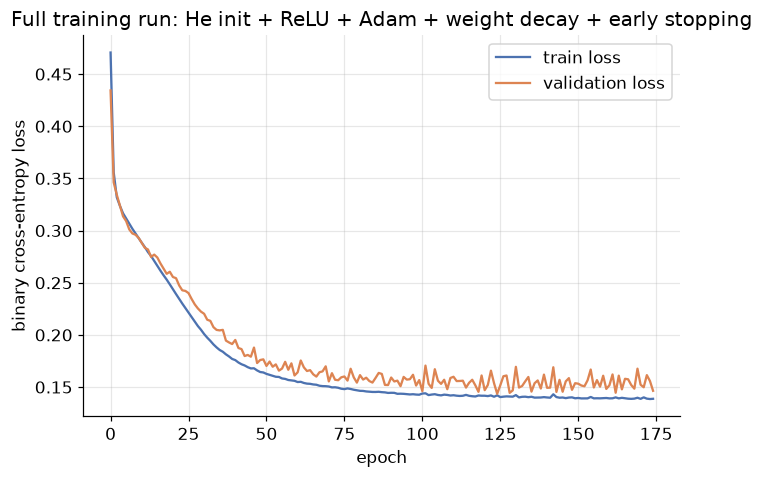

In [19]:
def train_network(X_tr, y_tr, X_va, y_va, n_hidden=16, lr=0.01, l2=1e-4,
                   batch_size=32, max_epochs=2000, patience=50,
                   beta1=0.9, beta2=0.999, eps=1e-8, seed=RANDOM_STATE):
    '''Mini-batch Adam training with He initialisation, weight decay and early stopping.'''
    n = X_tr.shape[0]
    p = init_params_v2(X_tr.shape[1], n_hidden, 1, method="he", seed=seed)
    m_moment = {k: np.zeros_like(v) for k, v in p.items()}
    v_moment = {k: np.zeros_like(v) for k, v in p.items()}
    rng = np.random.default_rng(seed)

    best_val_loss = np.inf
    best_params = None
    epochs_without_improvement = 0
    t = 0
    train_loss_history, val_loss_history = [], []

    for epoch in range(max_epochs):
        shuffled = rng.permutation(n)
        for start in range(0, n, batch_size):
            batch_idx = shuffled[start:start + batch_size]
            Xb, yb = X_tr[batch_idx], y_tr[batch_idx]

            a2, cache = forward(Xb, p)
            grads = backward(Xb, yb, p, cache, l2=l2)

            t += 1
            for key in p:
                m_moment[key] = beta1 * m_moment[key] + (1 - beta1) * grads[key]
                v_moment[key] = beta2 * v_moment[key] + (1 - beta2) * grads[key] ** 2
                m_hat = m_moment[key] / (1 - beta1 ** t)
                v_hat = v_moment[key] / (1 - beta2 ** t)
                p[key] = p[key] - lr * m_hat / (np.sqrt(v_hat) + eps)

        a2_tr, _ = forward(X_tr, p)
        a2_va, _ = forward(X_va, p)
        train_loss = compute_loss(y_tr, a2_tr)   # plain data loss for monitoring/early-stopping
        val_loss = compute_loss(y_va, a2_va)     # (l2 already shaped the gradient step above)
        train_loss_history.append(train_loss)
        val_loss_history.append(val_loss)

        if val_loss < best_val_loss - 1e-5:
            best_val_loss = val_loss
            best_params = {k: v.copy() for k, v in p.items()}
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= patience:
                break

    return best_params, train_loss_history, val_loss_history, epoch

our_params, our_train_loss, our_val_loss, stopped_at = train_network(
    X_train_s, y_train, X_val_s, y_val)

print(f"early stopping triggered after epoch {stopped_at} "
      f"(best validation loss at epoch {stopped_at - 50})")

plt.plot(our_train_loss, label="train loss")
plt.plot(our_val_loss, label="validation loss")
plt.xlabel("epoch"); plt.ylabel("binary cross-entropy loss")
plt.title("Full training run: He init + ReLU + Adam + weight decay + early stopping")
plt.legend()
plt.show()

No runaway overfitting this time — validation loss tracks training loss closely for as long as it keeps
falling, and training stops itself the moment it doesn't. Let's see what that trained network actually
learned, on the test set it has never touched.

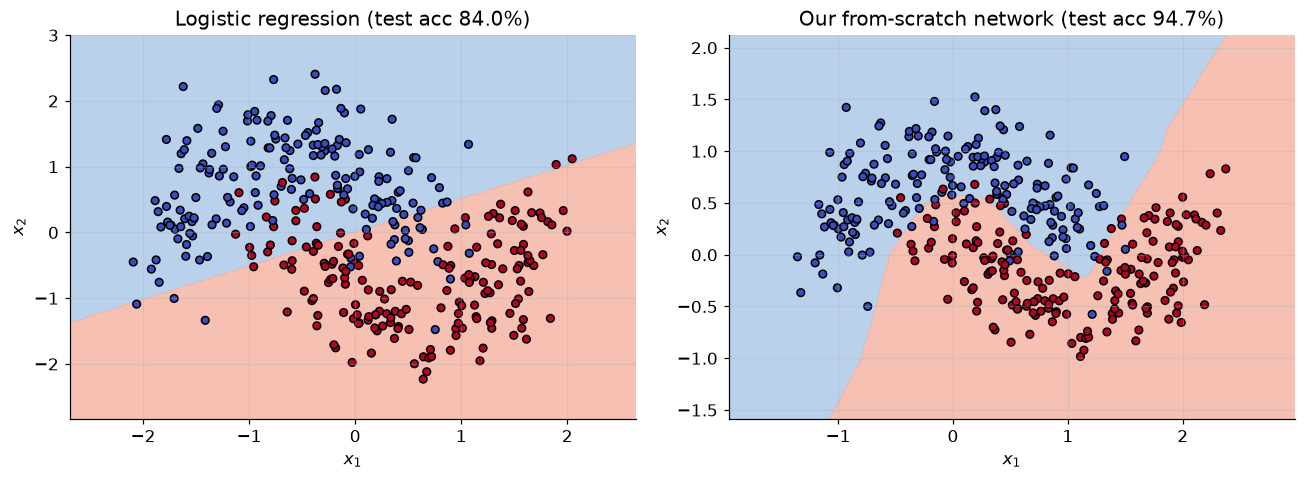

logistic regression test accuracy: 84.0%
our network test accuracy:         94.7%


In [20]:
def our_predict(X_raw):
    X_scaled = (X_raw - mu) / sigma
    a2, _ = forward(X_scaled, our_params)
    return (a2 > 0.5).astype(int)

our_test_acc = accuracy_score(y_test, our_predict(X_test))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
plot_decision_boundary(logreg.predict, X_train_s, y_train,
                        ax=axes[0], title=f"Logistic regression (test acc {logreg_acc:.1%})")
plot_decision_boundary(lambda Xg: our_predict(Xg).ravel(), X_train, y_train,
                        ax=axes[1], title=f"Our from-scratch network (test acc {our_test_acc:.1%})")
plt.tight_layout()
plt.show()

print(f"logistic regression test accuracy: {logreg_acc:.1%}")
print(f"our network test accuracy:         {our_test_acc:.1%}")

The straight boundary from Section 2 has become a curve that actually follows the two crescents — precisely
the payoff Section 2 promised a hidden layer would deliver, now realised end to end through initialisation,
activation, optimizer, regularization and early stopping working together.

---
## 12. The library shortcut: scikit-learn's `MLPClassifier`

Every mechanism in this notebook — forward pass, backpropagation, He initialisation, Adam, weight decay, early
stopping — is also sitting inside a single scikit-learn class: `sklearn.neural_network.MLPClassifier`. Its
hyperparameters map directly onto the sections above:

In [21]:
comparison_table = pd.DataFrame({
    "MLPClassifier argument": ["hidden_layer_sizes", "activation", "solver", "alpha",
                                "learning_rate_init", "early_stopping", "n_iter_no_change"],
    "what we built it as": ["n_hidden in init_params_v2 (Section 6)", "ReLU (Section 5)",
                             "'adam' == Section 7's Adam update", "l2, the weight-decay strength (Section 9)",
                             "lr, the Adam step size (Section 7)", "the early-stopping loop (Sections 9-11)",
                             "patience (Sections 9-11)"],
})
comparison_table

,MLPClassifier argument,what we built it as
0,hidden_layer_sizes,n_hidden in init_params_v2 (Section 6)
1,activation,ReLU (Section 5)
2,solver,'adam' == Section 7's Adam update
3,alpha,"l2, the weight-decay strength (Section 9)"
4,learning_rate_init,"lr, the Adam step size (Section 7)"
5,early_stopping,the early-stopping loop (Sections 9-11)
6,n_iter_no_change,patience (Sections 9-11)


In [22]:
sk_mlp = MLPClassifier(
    hidden_layer_sizes=(16,), activation="relu", solver="adam",
    alpha=1e-4, learning_rate_init=0.01, max_iter=2000,
    random_state=RANDOM_STATE,
).fit(X_train_s, y_train.ravel())

sk_test_acc = accuracy_score(y_test, sk_mlp.predict(X_test_s))

print(f"our from-scratch network:  test accuracy {our_test_acc:.1%}")
print(f"scikit-learn MLPClassifier: test accuracy {sk_test_acc:.1%}  (converged in {sk_mlp.n_iter_} iterations)")

our from-scratch network:  test accuracy 94.7%
scikit-learn MLPClassifier: test accuracy 92.0%  (converged in 323 iterations)


The two land in the same neighbourhood — reassuring confirmation that Sections 4 through 11 really did
reimplement what the library automates, rather than something merely similar-looking. One difference worth
noticing: scikit-learn's own `early_stopping=True` option carves off a small internal validation slice (10% of
the training set by default) and applies its *own* patience — which, on a dataset this small, can trigger
early with a noisier validation signal than the dedicated validation split we built by hand in Section 11.
That's a direct, concrete instance of Section 10's lesson: even a well-established default hyperparameter
(here, scikit-learn's `validation_fraction`) can behave differently on a small dataset than on the large ones
it was tuned against. In production, both approaches are legitimate — hand-rolled control when you need to
reason precisely about every knob (or when the architecture goes beyond what a library exposes), and a
library default when the standard recipe is exactly what the problem calls for.

---
## 13. Your turn

Add cells below each exercise. Exercises 2 and 5 are the ones that consolidate the big ideas.

**Exercise 1 — Swap the activation.**
`forward`/`backward` (Section 4) hard-code ReLU for the hidden layer. Duplicate them, swap in `tanh`/
`tanh_deriv` (Section 5) instead, retrain with `train_network`, and compare test accuracy and the decision
boundary against the ReLU version from Section 11. Does it still train cleanly with He initialisation, or
would Xavier (Section 6) be the more honest choice now?

**Exercise 2 — Break initialization on purpose.**
Call `propagate_forward` (Section 6) with `n_layers=20` and `tanh` activation, comparing `lambda n: 1.0`
(naive) against `lambda n: np.sqrt(1.0 / n)` (Xavier-ish, LeCun form). At what layer does the naive network's
saturation fraction cross 99%? Explain in one sentence, using Section 5's vanishing-gradient argument, why a
network that saturated that early would be nearly impossible to train.

**Exercise 3 — Momentum alone versus Adam.**
Modify `train_network` (Section 11) to use plain momentum (Section 7) instead of Adam — drop the RMSprop-style
second moment and its bias correction, keep only $v_t=\beta v_{t-1}+(1-\beta)g_t$. Train both versions for the
same number of epochs and compare validation-loss curves. Which converges faster on this dataset, and does
Section 7's ravine picture explain why?

**Exercise 4 — Noisier moons.**
Regenerate the dataset with `make_moons(n_samples=500, noise=0.4, random_state=RANDOM_STATE)` and rerun
Sections 11-12 end to end. Does the accuracy gap between logistic regression and the neural network grow or
shrink compared to `noise=0.25`? What does that imply about when the extra complexity of a hidden layer is
actually worth having?

**Exercise 5 — The full sweep.**
Extend Section 10's search to two hyperparameters at once: `n_hidden` and the weight-decay strength `l2`. Run
a small grid (e.g. `n_hidden in [8, 16, 32]`, `l2 in [0, 0.001, 0.01, 0.1]`), plot validation accuracy as a
heatmap (`seaborn.heatmap` on a pivoted DataFrame), and retrain a final network at the best combination using
`train_network`. Report its test accuracy alongside Section 12's scikit-learn comparison — does your tuned
version beat the untuned defaults from Section 11?

---
## 14. If you remember nothing else

1. A single neuron is a weighted sum plus an activation function — with a sigmoid activation, it's exactly
   logistic regression. Stacking neurons into layers only helps if a **non-linear** activation sits between
   them; stacked linear layers collapse algebraically into one linear layer.

2. **Backpropagation** is the chain rule, applied once per node of a computational graph, walking backward
   from the loss to every weight. Always verify a from-scratch implementation with a **numerical gradient
   check** before trusting it.

3. **Activation functions**: sigmoid for a binary output layer; ReLU as the default hidden-layer choice
   because its derivative doesn't shrink for active units (unlike sigmoid/tanh, which vanish at saturation);
   leaky ReLU as ReLU's fix for "dying" neurons.

4. **Weight initialization** must scale with layer width — all-zero or naive `N(0,1)` weights either freeze
   the network (symmetry) or blow up / vanish through depth. **He** ($\sqrt{2/n_{in}}$) for ReLU, **Xavier**
   ($\sqrt{2/(n_{in}+n_{out})}$) for tanh/sigmoid.

5. Beyond plain gradient descent: **momentum** averages the gradient itself; **RMSprop** rescales each
   parameter's step by its own gradient history; **Adam** combines both, and is deep learning's default
   optimizer. All three build on the same exponentially weighted moving average.

6. **Batch normalization** standardises a layer's activations across the mini-batch (plus a learnable rescale
   $\gamma,\beta$); **layer normalization** does the identical arithmetic across a single sample's features
   instead, which is what makes it usable without a batch at all.

7. **Early stopping** (restore the weights from the best validation epoch) and **weight decay** (an L2 penalty
   folded into the gradient) attack overfitting the same way regularization always has in this course — just
   inside a training loop instead of a closed-form fit.

8. Hyperparameters (architecture, learning rate, weight decay, patience, ...) are chosen, not learned. **Random
   search** usually beats **grid search** at the same compute budget once more than a couple of hyperparameters
   are in play, because it tests more distinct values of each one.

9. On our two-crescent dataset, wiring all of the above together took a straight-line logistic regression
   decision boundary to a curved one that actually separates the classes — and scikit-learn's
   `MLPClassifier` landed in the same neighbourhood, confirming the from-scratch implementation was correct
   rather than merely plausible.

---
## 15. Further reading and glossary

### Further reading

- Michael Nielsen, [*Neural Networks and Deep Learning*](http://neuralnetworksanddeeplearning.com/) — a free
  online book with an especially clear derivation of backpropagation.
- Ian Goodfellow, Yoshua Bengio & Aaron Courville, [*Deep Learning*](https://www.deeplearningbook.org/) —
  Chapters 6 (feedforward networks), 8 (optimization) and 11 (practical methodology) cover this module's
  material in full mathematical depth.
- Diederik Kingma & Jimmy Ba, [*Adam: A Method for Stochastic Optimization*](https://arxiv.org/abs/1412.6980)
  (2014) — the original Adam paper, short and readable.
- Sergey Ioffe & Christian Szegedy, [*Batch Normalization*](https://arxiv.org/abs/1502.03167) (2015), and
  Jimmy Lei Ba et al., [*Layer Normalization*](https://arxiv.org/abs/1607.06450) (2016) — the two normalization
  papers referenced in Section 8.
- James Bergstra & Yoshua Bengio, [*Random Search for Hyper-Parameter Optimization*](
  https://www.jmlr.org/papers/v13/bergstra12a.html) (2012) — the paper behind Section 10's grid-versus-random
  comparison.
- scikit-learn's guide to [neural network models](
  https://scikit-learn.org/stable/modules/neural_networks_supervised.html) — the full `MLPClassifier`/
  `MLPRegressor` API used in Section 12.

### Glossary

| Term | Meaning |
|---|---|
| Neuron | A weighted sum of inputs plus a bias, passed through an activation function. |
| Weight / bias | The learned parameters of a neuron ($w$) and its constant offset ($b$). |
| Activation function | The non-linearity applied after a neuron's weighted sum (sigmoid, tanh, ReLU, ...). |
| Computational graph | A diagram of operations (nodes) and values (edges) used to organise the chain rule. |
| Local gradient | A node's derivative of its own output with respect to its own input(s). |
| Backpropagation | Repeated application of the chain rule, walking a computational graph backward from the loss. |
| Vanishing gradient | Gradients shrinking toward zero through depth, typically from saturated sigmoid/tanh units. |
| Dying ReLU | A ReLU neuron stuck outputting zero (and gradient zero) because its weighted sum is permanently negative. |
| Xavier / Glorot initialization | Weight variance $2/(n_{in}+n_{out})$, suited to tanh/sigmoid hidden layers. |
| He initialization | Weight variance $2/n_{in}$, suited to ReLU hidden layers. |
| Exponentially weighted moving average (EWMA) | A running average that leans on recent history via a decay rate $\beta$. |
| Momentum | Gradient descent that averages the gradient itself via an EWMA before stepping. |
| RMSprop | Gradient descent that rescales each parameter's step by an EWMA of its squared gradient. |
| Adam | Momentum and RMSprop combined, with bias-corrected running averages; deep learning's default optimizer. |
| Batch normalization | Standardising a layer's activations across the mini-batch, then learnably rescaling ($\gamma,\beta$). |
| Layer normalization | The same standardisation computed across one sample's features instead of across the batch. |
| Internal covariate shift | The informal name for hidden-layer activation distributions drifting as earlier layers keep changing. |
| Early stopping | Restoring the weights from the training epoch with the best validation loss, rather than the last epoch. |
| Patience | The number of non-improving epochs early stopping tolerates before it actually stops. |
| Weight decay | An L2-style penalty folded directly into the gradient update, shrinking every weight toward zero. |
| Grid search | Hyperparameter tuning by evaluating every combination on a fixed grid of candidate values. |
| Random search | Hyperparameter tuning by evaluating randomly sampled combinations; usually more efficient than grid search. |
| Learning-rate schedule | A rule for shrinking the learning rate over the course of training (time-based, step, exponential, ...). |